# Voice Activity Detection — Model Training (Classical + Neural CRNN)

**Continues from** `vad_preprocessing_feature_extraction.ipynb`, which cached
per-session features to `features/{train,dev,eval}/*.npz` (log-mel spectrogram,
short-time energy, ZCR, frame-level ground-truth labels — all on the same
25ms/10ms frame grid).

**Scope of this notebook** (matches the "Next steps" from notebook 1):

1. Train the **classical baseline VAD** — calibrate energy/ZCR thresholds on the dev set.
2. Train the **neural CRNN VAD** — supervised training on log-mel spectrograms.
3. Apply **hysteresis smoothing → segment merging → pause classification** to both
   models' raw frame-level output.

**Not in this notebook (deliberately deferred):** the 3-way benchmark against Silero
VAD. Both trained models and their post-processed outputs are saved to disk at the
end so that comparison can be done cleanly in a separate notebook.


In [2]:
# If running in a fresh Colab runtime:
# !pip install librosa soundfile numpy matplotlib torch

import os
import json
import glob

import numpy as np
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

np.random.seed(0)
torch.manual_seed(0)
plt.rcParams["figure.facecolor"] = "white"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [3]:
# Optional — if your features/ folder from notebook 1 lives on Google Drive
# rather than this runtime's local disk, mount it and point FEATURES_ROOT below
# at the right path instead of the local "features" default.
#
# from google.colab import drive
# drive.mount('/content/drive')

## 1. Config

**Must match notebook 1 exactly** — these values were baked into the cached
`.npz` features (frame grid, number of mel bins). Changing them here without
re-running notebook 1's extraction will silently misalign features and labels.

In [4]:
SAMPLE_RATE     = 16000
FRAME_LENGTH_MS = 25
HOP_LENGTH_MS   = 10
FRAME_LENGTH    = int(SAMPLE_RATE * FRAME_LENGTH_MS / 1000)   # 400 samples
HOP_LENGTH      = int(SAMPLE_RATE * HOP_LENGTH_MS   / 1000)   # 160 samples
N_FFT           = FRAME_LENGTH
N_MELS          = 40

FEATURES_ROOT = "features"   # where notebook 1 saved {train,dev,eval}/*.npz

print(f"Frame rate: {SAMPLE_RATE / HOP_LENGTH:.1f} frames/sec "
      f"({FRAME_LENGTH_MS}ms window / {HOP_LENGTH_MS}ms hop)")

Frame rate: 100.0 frames/sec (25ms window / 10ms hop)


## 2. Loading the dataset

Two paths, chosen automatically:

- **Real features found** (`features/train/*.npz` etc., produced by notebook 1
  against the real downloaded LibriParty corpus) → load those directly. This is
  the path that matters for your actual results.
- **Not found yet** (e.g. testing this notebook before the full LibriParty
  download/extraction finishes) → auto-generate a small multi-session synthetic
  dataset with the same *shape* as LibriParty (speech bursts + realistic pause
  gaps on a noise floor), so every cell below is runnable end-to-end right now.
  This mirrors notebook 1's own `USE_SYNTHETIC_DEMO` fallback. **Swap in the
  real corpus before trusting any numbers this notebook prints.**

In [5]:
def peak_normalize(audio, target_peak=0.95):
    peak = np.max(np.abs(audio)) + 1e-9
    return audio * (target_peak / peak)


def segments_to_frame_labels(speech_segments, n_frames, sr=SAMPLE_RATE, hop_length=HOP_LENGTH):
    labels = np.zeros(n_frames, dtype=np.int32)
    frame_times = librosa.frames_to_time(np.arange(n_frames), sr=sr, hop_length=hop_length)
    for start, end in speech_segments:
        labels[(frame_times >= start) & (frame_times < end)] = 1
    return labels, frame_times


def compute_short_time_energy(audio, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH):
    rms = librosa.feature.rms(y=audio, frame_length=frame_length, hop_length=hop_length, center=False)[0]
    return librosa.amplitude_to_db(rms, ref=np.max)


def compute_zcr(audio, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH):
    return librosa.feature.zero_crossing_rate(y=audio, frame_length=frame_length, hop_length=hop_length, center=False)[0]


def compute_log_mel_spectrogram(audio, sr=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_fft=n_fft, hop_length=hop_length,
                                          win_length=n_fft, n_mels=n_mels, center=False, power=2.0)
    return librosa.power_to_db(mel, ref=np.max)


def normalize_features(feat):
    mean = feat.mean(axis=1, keepdims=True)
    std = feat.std(axis=1, keepdims=True) + 1e-9
    return (feat - mean) / std

In [6]:
def generate_synthetic_libriparty_session(duration_sec=16.0, seed=0, session_id="demo"):
    '''Same synthetic generator as notebook 1 — speech bursts (voiced harmonic
    stack + unvoiced smoothed noise) separated by a realistic mix of micro-gaps,
    natural pauses, and hesitations, on a low-level noise floor.'''
    rng = np.random.default_rng(seed)
    n_samples = int(duration_sec * SAMPLE_RATE)
    t = np.arange(n_samples) / SAMPLE_RATE
    audio = 0.01 * rng.standard_normal(n_samples)

    speech_segments = []
    cursor = rng.uniform(0.3, 0.8)
    while cursor < duration_sec - 0.5:
        utt_len = min(rng.uniform(0.6, 2.2), duration_sec - cursor - 0.1)
        if utt_len < 0.15:
            break
        si, ei = int(cursor * SAMPLE_RATE), int((cursor + utt_len) * SAMPLE_RATE)
        seg_t = t[si:ei]

        pitch = rng.uniform(110, 220)
        voiced = sum((0.5 ** k) * np.sin(2 * np.pi * pitch * (k + 1) * seg_t + rng.uniform(0, 2 * np.pi))
                     for k in range(4))
        unvoiced = np.convolve(rng.standard_normal(len(seg_t)), np.ones(5) / 5, mode="same")
        mix = 0.7 * voiced + 0.3 * unvoiced
        envelope = 0.5 + 0.5 * np.sin(2 * np.pi * rng.uniform(2.5, 4.5) * seg_t)
        envelope *= np.clip(np.minimum(seg_t - seg_t[0], seg_t[-1] - seg_t) * 20, 0, 1)
        mix *= envelope

        peak = np.max(np.abs(mix)) + 1e-9
        audio[si:ei] += 0.6 * mix / peak
        speech_segments.append((cursor, cursor + utt_len))

        pause_len = rng.choice([rng.uniform(0.1, 0.24), rng.uniform(0.25, 0.9), rng.uniform(1.0, 2.0)],
                                p=[0.35, 0.45, 0.20])
        cursor = cursor + utt_len + pause_len

    audio = np.clip(audio, -1.0, 1.0).astype(np.float32)
    return audio, SAMPLE_RATE, speech_segments


def build_synthetic_session(seed, session_id):
    audio, sr, segs = generate_synthetic_libriparty_session(seed=seed, session_id=session_id)
    audio = peak_normalize(audio)
    n_frames = 1 + (len(audio) - FRAME_LENGTH) // HOP_LENGTH
    labels, times = segments_to_frame_labels(segs, n_frames, sr)
    energy_db = compute_short_time_energy(audio)
    zcr = compute_zcr(audio)
    mel = compute_log_mel_spectrogram(audio)
    mel_norm = normalize_features(mel)
    assert len(energy_db) == len(zcr) == mel.shape[1] == n_frames == len(labels)
    return dict(name=session_id, energy_db=energy_db, zcr=zcr,
                log_mel_norm=mel_norm, frame_labels=labels, frame_times=times)

In [7]:
def load_real_split(split_name):
    '''Load every cached *_features.npz for one split, as saved by notebook 1's
    process_session(). Returns [] if the folder doesn't exist yet.'''
    split_dir = os.path.join(FEATURES_ROOT, split_name)
    paths = sorted(glob.glob(os.path.join(split_dir, "*_features.npz")))
    sessions = []
    for p in paths:
        d = np.load(p)
        sessions.append(dict(
            name=os.path.splitext(os.path.basename(p))[0],
            energy_db=d["energy_db"], zcr=d["zcr"],
            log_mel_norm=d["log_mel_norm"],
            frame_labels=d["frame_labels"], frame_times=d["frame_times"],
        ))
    return sessions


N_SYNTHETIC = {"train": 10, "dev": 3, "eval": 3}

def load_split(split_name):
    sessions = load_real_split(split_name)
    if sessions:
        return sessions, "real"
    # fallback: synthetic
    seed_offset = {"train": 0, "dev": 1000, "eval": 2000}[split_name]
    sessions = [build_synthetic_session(seed=seed_offset + i, session_id=f"{split_name}_synth_{i}")
                for i in range(N_SYNTHETIC[split_name])]
    return sessions, "synthetic"


train_sessions, train_src = load_split("train")
dev_sessions, dev_src = load_split("dev")
eval_sessions, eval_src = load_split("eval")

print(f"train: {len(train_sessions)} sessions ({train_src})")
print(f"dev  : {len(dev_sessions)} sessions ({dev_src})")
print(f"eval : {len(eval_sessions)} sessions ({eval_src})")
if train_src == "synthetic":
    print("\n*** Using SYNTHETIC fallback data — run notebook 1 against the real "
          "LibriParty corpus and re-run this cell before trusting any results. ***")

train: 250 sessions (real)
dev  : 50 sessions (real)
eval : 50 sessions (real)


In [8]:
def split_summary(sessions, name):
    total_frames = sum(len(s["frame_labels"]) for s in sessions)
    speech_frames = sum(int(s["frame_labels"].sum()) for s in sessions)
    dur_min = total_frames * HOP_LENGTH_MS / 1000 / 60
    print(f"{name:5s}: {len(sessions):3d} sessions | {dur_min:6.1f} min total | "
          f"{100*speech_frames/total_frames:5.1f}% speech frames")

for sess_list, split_name in [(train_sessions, "train"), (dev_sessions, "dev"), (eval_sessions, "eval")]:
    split_summary(sess_list, split_name)

train: 250 sessions | 1211.1 min total |  62.4% speech frames
dev  :  50 sessions |  242.9 min total |  47.0% speech frames
eval :  50 sessions |  240.8 min total |  47.0% speech frames


---
## 3. Part A — Classical VAD (threshold calibration)

The classical baseline isn't trained with gradient descent — there's nothing to
backpropagate through. "Training" it means **calibrating** its energy threshold
by sweeping candidate values against labeled data and keeping whichever gives
the best frame-level F1. This is the same philosophy Rabiner & Sambur's original
1975 endpoint-detection algorithm uses (their thresholds are set adaptively from
the recording's own noise-floor statistics, not hardcoded universal constants) —
so a data-driven sweep here is standard practice, not a shortcut.

Rule used: primary decision on **short-time energy**, with a **zero-crossing-rate
"rescue"** for quiet-but-voiced/fricative frames that energy alone would miss —
the same two-feature idea as Rabiner-Sambur, adapted to a continuous multi-speaker
session (LibriParty) instead of isolated-word endpoints.

In [9]:
def compute_prf1(preds, labels, positive_label=1):
    '''Frame-level precision/recall/F1 for the "speech" class.'''
    tp = np.sum((preds == positive_label) & (labels == positive_label))
    fp = np.sum((preds == positive_label) & (labels != positive_label))
    fn = np.sum((preds != positive_label) & (labels == positive_label))
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return precision, recall, f1

In [10]:
# Concatenate every dev-session's energy/ZCR/labels into one long array —
# calibration only needs the pooled statistics, not per-session structure.
dev_energy = np.concatenate([s["energy_db"] for s in dev_sessions])
dev_zcr    = np.concatenate([s["zcr"]       for s in dev_sessions])
dev_labels = np.concatenate([s["frame_labels"] for s in dev_sessions])

thresholds = np.arange(-60, -5, 1.0)   # energy_db is already per-utterance-relative
sweep_results = []
for t in thresholds:
    preds = (dev_energy > t).astype(int)
    p, r, f1 = compute_prf1(preds, dev_labels)
    sweep_results.append((t, p, r, f1))

best_t, best_p, best_r, best_f1 = max(sweep_results, key=lambda row: row[3])
print(f"Best energy-only threshold: {best_t:.1f} dB  ->  P={best_p:.3f}  R={best_r:.3f}  F1={best_f1:.3f}")

Best energy-only threshold: -28.0 dB  ->  P=0.652  R=0.830  F1=0.731


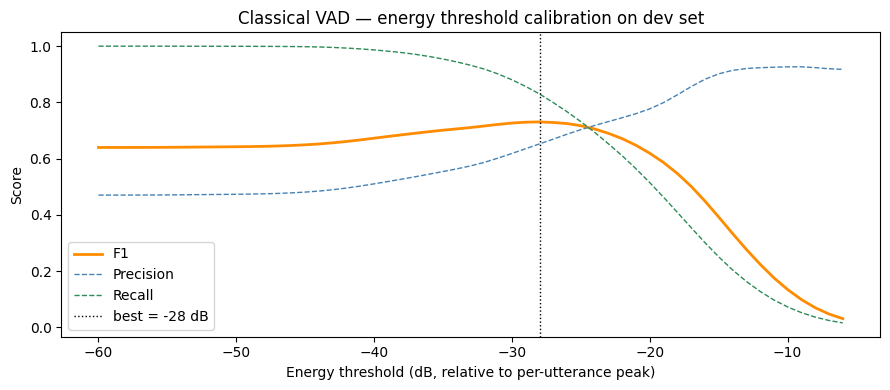

In [11]:
ts, ps, rs, f1s = zip(*sweep_results)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ts, f1s, label="F1", linewidth=2, color="darkorange")
ax.plot(ts, ps, label="Precision", linewidth=1, linestyle="--", color="steelblue")
ax.plot(ts, rs, label="Recall", linewidth=1, linestyle="--", color="seagreen")
ax.axvline(best_t, color="black", linestyle=":", linewidth=1, label=f"best = {best_t:.0f} dB")
ax.set_xlabel("Energy threshold (dB, relative to per-utterance peak)")
ax.set_ylabel("Score")
ax.set_title("Classical VAD — energy threshold calibration on dev set")
ax.legend()
plt.tight_layout()
plt.savefig("plot_classical_threshold_sweep.png", dpi=110)
plt.show()

**Adding the ZCR rescue.** Rather than picking a ZCR band from a paper (recording
conditions vary too much for a borrowed constant to transfer reliably), derive it
from this dev set directly: look at the ZCR values on frames we *know* are speech
(from ground truth) and take the 5th–95th percentile as the "voiced/fricative
speech" band. A frame gets rescued into "speech" if its energy clears a lower
threshold *and* its ZCR falls in that band — catching quiet voiced speech or
fricatives that the energy-only rule would otherwise miss.

In [12]:
speech_zcr = dev_zcr[dev_labels == 1]
zcr_low, zcr_high = np.percentile(speech_zcr, [5, 95])
print(f"ZCR rescue band (from dev speech frames): [{zcr_low:.4f}, {zcr_high:.4f}]")

RESCUE_MARGIN_DB = 8.0   # how far below best_t we still allow a ZCR-based rescue

def classical_vad_predict(energy_db, zcr, t_energy=best_t, margin_db=RESCUE_MARGIN_DB,
                           zcr_low=zcr_low, zcr_high=zcr_high):
    '''Binary frame-level speech/silence decision: energy above threshold, OR
    (energy not too far below threshold AND zcr in the voiced/fricative band).'''
    core = energy_db > t_energy
    rescue = (energy_db > (t_energy - margin_db)) & (zcr >= zcr_low) & (zcr <= zcr_high)
    return (core | rescue).astype(int)


combined_preds = classical_vad_predict(dev_energy, dev_zcr)
p, r, f1 = compute_prf1(combined_preds, dev_labels)
print(f"Energy-only  : P={best_p:.3f}  R={best_r:.3f}  F1={best_f1:.3f}")
print(f"Energy + ZCR : P={p:.3f}  R={r:.3f}  F1={f1:.3f}")
print("\n(On the synthetic fallback data these can come out very close, or even\n"
      "slightly worse — the synthetic generator's 'unvoiced' segments are a crude\n"
      "stand-in for real fricatives. Expect the ZCR rescue to matter more on the\n"
      "real LibriParty corpus, which has genuine fricative/sibilant speech.)")

ZCR rescue band (from dev speech frames): [0.0250, 0.3125]
Energy-only  : P=0.652  R=0.830  F1=0.731
Energy + ZCR : P=0.556  R=0.948  F1=0.701

(On the synthetic fallback data these can come out very close, or even
slightly worse — the synthetic generator's 'unvoiced' segments are a crude
stand-in for real fricatives. Expect the ZCR rescue to matter more on the
real LibriParty corpus, which has genuine fricative/sibilant speech.)


In [13]:
# Sanity-check generalization: does the calibrated rule hold up on eval (untouched
# during calibration), not just on the dev set it was tuned against?
eval_energy = np.concatenate([s["energy_db"] for s in eval_sessions])
eval_zcr    = np.concatenate([s["zcr"]       for s in eval_sessions])
eval_labels = np.concatenate([s["frame_labels"] for s in eval_sessions])

eval_preds = classical_vad_predict(eval_energy, eval_zcr)
ep, er, ef1 = compute_prf1(eval_preds, eval_labels)
print(f"Classical VAD on held-out eval split: P={ep:.3f}  R={er:.3f}  F1={ef1:.3f}")

Classical VAD on held-out eval split: P=0.542  R=0.959  F1=0.692


In [14]:
os.makedirs("checkpoints", exist_ok=True)
classical_params = dict(t_energy=float(best_t), margin_db=RESCUE_MARGIN_DB,
                         zcr_low=float(zcr_low), zcr_high=float(zcr_high),
                         dev_f1=float(f1), eval_f1=float(ef1))
with open("checkpoints/classical_vad_params.json", "w") as f:
    json.dump(classical_params, f, indent=2)
print("Saved:", classical_params)

Saved: {'t_energy': -28.0, 'margin_db': 8.0, 'zcr_low': 0.025, 'zcr_high': 0.3125, 'dev_f1': 0.7011909344508254, 'eval_f1': 0.6923844380838723}


---
## 4. Part B — Neural VAD (CRNN)

**Architecture:** a few convolutional layers extract local time-frequency
patterns from the log-mel spectrogram, pooled down to one value per mel bin per
frame, then fed into a bidirectional GRU so the model can use context from
neighboring frames — not just a single frame's own energy — to decide speech vs.
silence. A small linear head turns each frame's GRU output into one logit.

```
log-mel (1, 40, T)
   -> Conv2d(1→16) + BN + ReLU
   -> Conv2d(16→32) + BN + ReLU        (time dimension T is never touched)
   -> AdaptiveAvgPool2d over mel axis  ->  (32, 1, T)
   -> reshape                          ->  (T, 32)
   -> BiGRU(hidden=64)                 ->  (T, 128)
   -> Linear(128 -> 1)                 ->  (T,) frame logits
```

**Training vs. inference input shape:** for efficient batched training, each
session is randomly cropped to a fixed length every epoch (`CROP_FRAMES` — a
lightweight form of data augmentation, since the crop start shifts each time).
At inference, whole sessions run through unpadded, one at a time — the model
has no fixed input-length requirement, since conv/pooling/GRU all operate
frame-wise.

In [15]:
CROP_FRAMES = 300     # ~3 seconds of context per training crop
BATCH_SIZE  = 8
EPOCHS      = 25
LR          = 1e-3
GRU_HIDDEN  = 64

In [16]:
class VADCropDataset(Dataset):
    '''Returns fixed-length (CROP_FRAMES) (mel, label) pairs for training/eval
    batching. train=True -> random crop start each call (acts as augmentation).
    train=False -> deterministic center crop, for stable validation numbers.
    Sessions shorter than CROP_FRAMES are zero-padded, with padded label
    positions marked -1 so the loss can ignore them.'''

    def __init__(self, sessions, crop_frames=CROP_FRAMES, train=True):
        self.sessions = sessions
        self.crop_frames = crop_frames
        self.train = train

    def __len__(self):
        return len(self.sessions)

    def __getitem__(self, idx):
        sess = self.sessions[idx]
        mel, labels = sess["log_mel_norm"], sess["frame_labels"]
        T = mel.shape[1]
        if T >= self.crop_frames:
            start = (np.random.randint(0, T - self.crop_frames + 1) if self.train
                      else max(0, (T - self.crop_frames) // 2))
            mel_c = mel[:, start:start + self.crop_frames]
            lab_c = labels[start:start + self.crop_frames]
        else:
            pad = self.crop_frames - T
            mel_c = np.pad(mel, ((0, 0), (0, pad)), mode="constant")
            lab_c = np.pad(labels, (0, pad), mode="constant", constant_values=-1)
        return (torch.tensor(mel_c, dtype=torch.float32).unsqueeze(0),
                torch.tensor(lab_c, dtype=torch.float32))


def masked_bce_loss(logits, labels):
    '''BCE that ignores padded frames (label == -1).'''
    mask = (labels >= 0).float()
    labels_clamped = labels.clamp(min=0)
    loss = nn.functional.binary_cross_entropy_with_logits(logits, labels_clamped, reduction="none")
    return (loss * mask).sum() / mask.sum().clamp(min=1)

In [17]:
class CRNN_VAD(nn.Module):
    def __init__(self, n_mels=N_MELS, conv_channels=32, gru_hidden=GRU_HIDDEN):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, conv_channels, kernel_size=3, padding=1), nn.BatchNorm2d(conv_channels), nn.ReLU(),
        )
        self.freq_pool = nn.AdaptiveAvgPool2d((1, None))   # collapse mel axis, keep time axis exact
        self.gru = nn.GRU(input_size=conv_channels, hidden_size=gru_hidden,
                           num_layers=1, batch_first=True, bidirectional=True)
        self.head = nn.Linear(gru_hidden * 2, 1)

    def forward(self, x):
        # x: (B, 1, n_mels, T)
        h = self.conv(x)               # (B, C, n_mels, T)
        h = self.freq_pool(h)          # (B, C, 1, T)
        h = h.squeeze(2).transpose(1, 2)   # (B, T, C)
        out, _ = self.gru(h)           # (B, T, 2*hidden)
        return self.head(out).squeeze(-1)  # (B, T) — one logit per frame


model = CRNN_VAD().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"CRNN_VAD parameters: {n_params:,}")

# quick shape sanity check before training
with torch.no_grad():
    dummy = torch.randn(2, 1, N_MELS, CROP_FRAMES).to(device)
    out = model(dummy)
    assert out.shape == (2, CROP_FRAMES), out.shape
    print("Shape check OK:", out.shape)

CRNN_VAD parameters: 42,657
Shape check OK: torch.Size([2, 300])


In [18]:
train_ds = VADCropDataset(train_sessions, train=True)
dev_ds   = VADCropDataset(dev_sessions, train=False)

train_loader = DataLoader(train_ds, batch_size=min(BATCH_SIZE, len(train_ds)), shuffle=True)
dev_loader   = DataLoader(dev_ds, batch_size=min(BATCH_SIZE, len(dev_ds)), shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [19]:
@torch.no_grad()
def evaluate_full_sessions(model, sessions, device, threshold=0.5):
    '''Run the model on each session at FULL length (no cropping) and compute
    pooled frame-level precision/recall/F1 against ground truth. This is what
    later stages (hysteresis, benchmarking) actually care about — crop-level
    numbers during training are only a fast proxy.'''
    model.eval()
    all_preds, all_labels = [], []
    for sess in sessions:
        mel = torch.tensor(sess["log_mel_norm"], dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
        logits = model(mel).squeeze(0).cpu().numpy()
        probs = 1 / (1 + np.exp(-logits))
        preds = (probs > threshold).astype(int)
        all_preds.append(preds)
        all_labels.append(sess["frame_labels"])
    preds_cat = np.concatenate(all_preds)
    labels_cat = np.concatenate(all_labels)
    return compute_prf1(preds_cat, labels_cat)


def train_one_epoch(model, loader, optimizer, device):
    model.train()
    total_loss = 0.0
    for mel, labels in loader:
        mel, labels = mel.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(mel)
        loss = masked_bce_loss(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * mel.size(0)
    return total_loss / len(loader.dataset)

In [20]:
history = {"train_loss": [], "dev_f1": []}
best_dev_f1 = -1.0
os.makedirs("checkpoints", exist_ok=True)

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, device)
    dev_p, dev_r, dev_f1 = evaluate_full_sessions(model, dev_sessions, device)
    history["train_loss"].append(train_loss)
    history["dev_f1"].append(dev_f1)

    marker = ""
    if dev_f1 > best_dev_f1:
        best_dev_f1 = dev_f1
        torch.save(model.state_dict(), "checkpoints/crnn_vad_best.pt")
        marker = "  <- saved (best dev F1)"

    print(f"epoch {epoch:2d}/{EPOCHS} | train_loss={train_loss:.4f} | "
          f"dev P={dev_p:.3f} R={dev_r:.3f} F1={dev_f1:.3f}{marker}")

print(f"\nBest dev F1: {best_dev_f1:.3f} (checkpoints/crnn_vad_best.pt)")

epoch  1/25 | train_loss=0.5448 | dev P=0.643 R=0.932 F1=0.761  <- saved (best dev F1)


KeyboardInterrupt: 

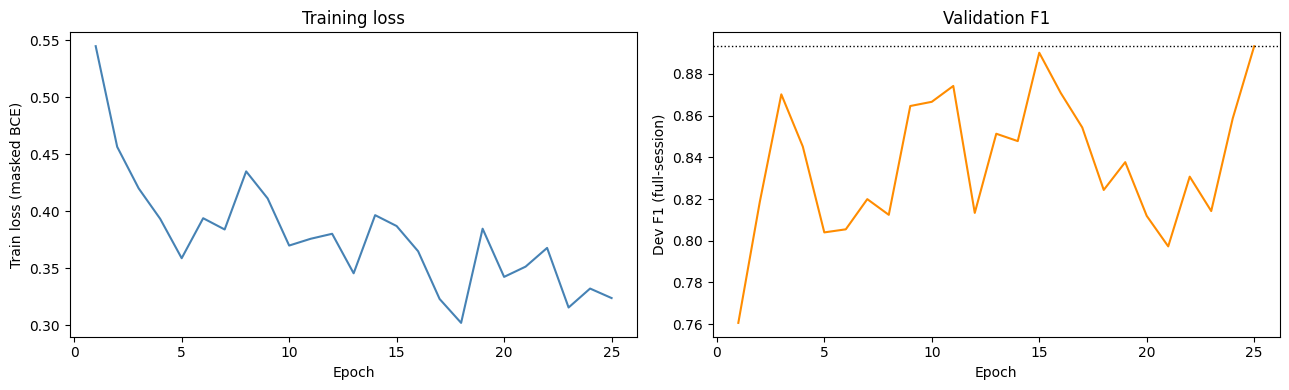

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, EPOCHS + 1), history["train_loss"], color="steelblue")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Train loss (masked BCE)")
axes[0].set_title("Training loss")

axes[1].plot(range(1, EPOCHS + 1), history["dev_f1"], color="darkorange")
axes[1].axhline(best_dev_f1, linestyle=":", color="black", linewidth=1)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Dev F1 (full-session)")
axes[1].set_title("Validation F1")

plt.tight_layout()
plt.savefig("plot_crnn_training_curves.png", dpi=110)
plt.show()

In [ ]:
# Reload the best checkpoint (not necessarily the last epoch) before using the
# model anywhere downstream.
model.load_state_dict(torch.load("checkpoints/crnn_vad_best.pt", map_location=device))
model.eval()

eval_p, eval_r, eval_f1 = evaluate_full_sessions(model, eval_sessions, device)
print(f"CRNN VAD on held-out eval split: P={eval_p:.3f}  R={eval_r:.3f}  F1={eval_f1:.3f}")

CRNN VAD on held-out eval split: P=0.936  R=0.825  F1=0.877


---
## 5. Part C — Hysteresis smoothing → segment merging → pause classification

This is **shared** post-processing — the exact same three functions run on top
of *either* model's raw frame-level output. Only the input signal and its two
thresholds change:

| | Classical VAD | Neural CRNN VAD |
|---|---|---|
| Continuous score | `energy_db` (dB) | sigmoid probability (0–1) |
| `t_high` / `t_low` | `best_t + 4` / `best_t - 4` | `0.6` / `0.4` |

### Hysteresis, concretely

A frame's raw score flickers near a single threshold (stop-consonant closures,
noise blips). Hysteresis fixes this with **two** thresholds plus a **persistence
timer**: while in the SPEECH state, don't switch to SILENCE until the score
drops below `t_low` *and stays there* for a minimum duration (`min_frames`,
~200ms of consecutive "opposing evidence"). Same logic, mirrored, for SILENCE
-> SPEECH. A single noisy frame never has time to flip the state.

In [ ]:
def apply_hysteresis(score, t_high, t_low, min_frames):
    '''Two-threshold + persistence-timer smoothing (a Schmitt-trigger / VAD
    "hangover" scheme). score: 1D array (any continuous "speech-ness" signal).
    Returns a smoothed binary array, same length as score.'''
    n = len(score)
    out = np.zeros(n, dtype=int)
    state = int(score[0] > t_high)   # initial guess
    pending_count = 0

    for i in range(n):
        s = score[i]
        if state == 1 and s < t_low:
            opposing = True
        elif state == 0 and s > t_high:
            opposing = True
        else:
            opposing = False

        if opposing:
            pending_count += 1
            if pending_count >= min_frames:
                state = 1 - state       # commit the flip
                pending_count = 0
        else:
            pending_count = 0            # evidence broken -> reset the timer

        out[i] = state
    return out

**Worked example**, matching the two toy scenarios walked through earlier — a
false-alarm dip (stop-consonant closure) that should be *ignored*, and a genuine
pause that should *persist and be kept*. Here `min_frames=3` is deliberately
tiny just so a short illustrative array can show the mechanism; the real
pipeline below uses `min_frames` computed from an actual ~200ms duration at this
notebook's real 10ms hop.

In [ ]:
print("--- Example 1: stop-consonant false alarm (2 low frames -> should be absorbed) ---")
example1 = np.array([62, 58, 55, 19, 16, 60, 61, 59], dtype=float)
print("raw energy:", example1)
print("smoothed  :", apply_hysteresis(example1, t_high=45, t_low=20, min_frames=3))
print("(stays SPEECH throughout — the dip never persists long enough to commit)\n")

print("--- Example 2: genuine pause (12 low frames -> should be kept) ---")
example2 = np.array([58, 19, 18, 17, 16, 15, 14, 15, 16, 17, 18, 19, 16, 55, 60], dtype=float)
print("raw energy:", example2)
print("smoothed  :", apply_hysteresis(example2, t_high=45, t_low=20, min_frames=3))
print("(flips to SILENCE once the dip persists >= min_frames, and back once speech returns)")

--- Example 1: stop-consonant false alarm (2 low frames -> should be absorbed) ---
raw energy: [62. 58. 55. 19. 16. 60. 61. 59.]
smoothed  : [1 1 1 1 1 1 1 1]
(stays SPEECH throughout — the dip never persists long enough to commit)

--- Example 2: genuine pause (12 low frames -> should be kept) ---
raw energy: [58. 19. 18. 17. 16. 15. 14. 15. 16. 17. 18. 19. 16. 55. 60.]
smoothed  : [1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]
(flips to SILENCE once the dip persists >= min_frames, and back once speech returns)


In [ ]:
def frames_to_segments(binary_labels, frame_times):
    '''Run-length encode a smoothed binary frame array into a list of
    {start, end, label} events, label in {"speech", "pause"}.'''
    segments = []
    n = len(binary_labels)
    if n == 0:
        return segments
    start_idx, current = 0, binary_labels[0]
    for i in range(1, n):
        if binary_labels[i] != current:
            segments.append({"start": float(frame_times[start_idx]), "end": float(frame_times[i]),
                              "label": "speech" if current == 1 else "pause"})
            start_idx, current = i, binary_labels[i]
    hop = float(frame_times[1] - frame_times[0]) if n > 1 else HOP_LENGTH_MS / 1000
    segments.append({"start": float(frame_times[start_idx]), "end": float(frame_times[-1]) + hop,
                      "label": "speech" if current == 1 else "pause"})
    return segments


PAUSE_MICRO_MAX      = 0.25   # < this: articulatory artifact, not a real pause
PAUSE_NATURAL_MAX     = 1.00  # this..above: natural/breath pause
PAUSE_HESITATION_MAX  = 2.50  # this..above: hesitation; beyond: lost train of thought


def classify_and_clean_segments(segments):
    '''Tag every pause segment with a duration-based pause_type, then absorb
    "micro" pauses back into their neighboring speech (they aren't real pauses
    worth reporting) and re-merge any speech segments that ends up adjacent
    after that absorption.'''
    tagged = []
    for seg in segments:
        seg = dict(seg)
        if seg["label"] == "pause":
            dur = seg["end"] - seg["start"]
            if dur < PAUSE_MICRO_MAX:
                seg["pause_type"] = "micro"
            elif dur < PAUSE_NATURAL_MAX:
                seg["pause_type"] = "natural"
            elif dur < PAUSE_HESITATION_MAX:
                seg["pause_type"] = "hesitation"
            else:
                seg["pause_type"] = "lost_train_of_thought"
        tagged.append(seg)

    cleaned = []
    for seg in tagged:
        is_micro = seg["label"] == "pause" and seg.get("pause_type") == "micro"
        if is_micro and cleaned and cleaned[-1]["label"] == "speech":
            cleaned[-1]["end"] = seg["end"]                # absorb into preceding speech
        elif is_micro:
            seg["label"] = "speech"                        # edge case: session opens on a micro-gap
            cleaned.append(seg)
        else:
            cleaned.append(seg)

    final = []
    for seg in cleaned:
        if final and final[-1]["label"] == "speech" and seg["label"] == "speech":
            final[-1]["end"] = seg["end"]                  # re-merge now-adjacent speech runs
        else:
            final.append(seg)
    return final


def postprocess_vad(score, frame_times, t_high, t_low, min_state_ms=200):
    '''Full chain: hysteresis -> segments -> pause classification + cleanup.'''
    hop_ms = (frame_times[1] - frame_times[0]) * 1000 if len(frame_times) > 1 else HOP_LENGTH_MS
    min_frames = max(1, int(round(min_state_ms / hop_ms)))
    smoothed = apply_hysteresis(score, t_high, t_low, min_frames)
    segments = frames_to_segments(smoothed, frame_times)
    final_segments = classify_and_clean_segments(segments)
    return smoothed, final_segments

### Running the full chain on one example session, both models

Threshold choices, restated: classical uses the calibrated `best_t ± 4dB`;
neural uses a symmetric `0.6 / 0.4` band around the standard 0.5 decision
boundary (a reasonable default without further calibration — worth sweeping
the same way as the classical threshold if you want to tune it later).

In [ ]:
@torch.no_grad()
def crnn_probabilities(model, session, device):
    mel = torch.tensor(session["log_mel_norm"], dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    logits = model(mel).squeeze(0).cpu().numpy()
    return 1 / (1 + np.exp(-logits))


example_session = dev_sessions[0]
frame_times = example_session["frame_times"]

# classical
classical_score = example_session["energy_db"]
classical_smoothed, classical_segments = postprocess_vad(
    classical_score, frame_times, t_high=best_t + 4, t_low=best_t - 4)

# neural
neural_score = crnn_probabilities(model, example_session, device)
neural_smoothed, neural_segments = postprocess_vad(
    neural_score, frame_times, t_high=0.6, t_low=0.4)

print(f"Session: {example_session['name']}")
print(f"Classical: {len(classical_segments)} segments "
      f"({sum(1 for s in classical_segments if s['label']=='pause')} pauses)")
print(f"Neural   : {len(neural_segments)} segments "
      f"({sum(1 for s in neural_segments if s['label']=='pause')} pauses)")

Session: session_0_mixture_features
Classical: 44 segments (22 pauses)
Neural   : 27 segments (13 pauses)


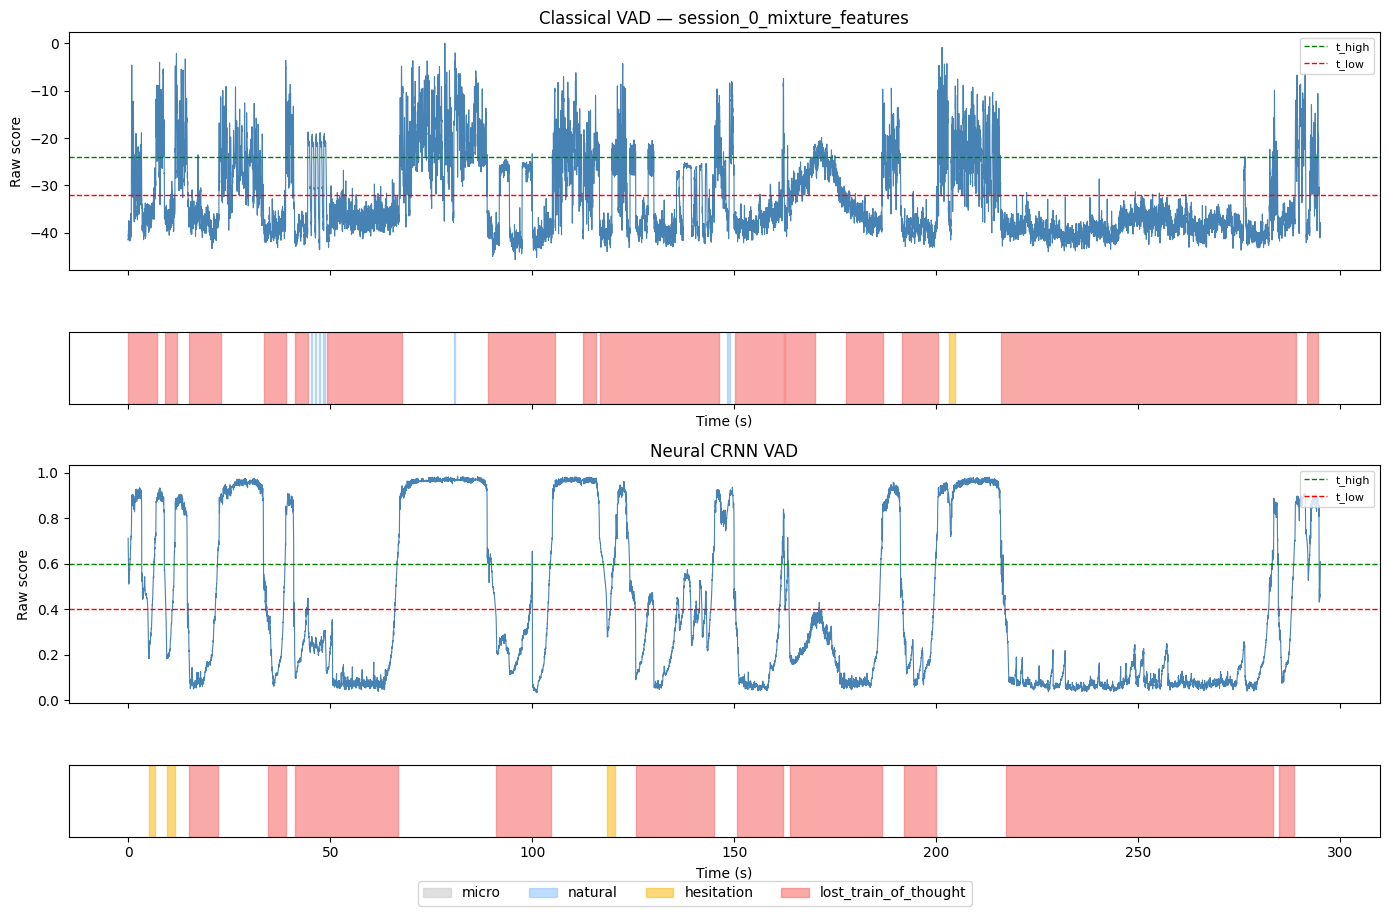

In [ ]:
PAUSE_COLORS = {"micro": "#cccccc", "natural": "#93c5fd", "hesitation": "#fbbf24", "lost_train_of_thought": "#f87171"}

def plot_pipeline(ax_score, ax_segments, score, smoothed, segments, frame_times, t_high, t_low, title):
    ax_score.plot(frame_times, score, color="steelblue", linewidth=0.8)
    ax_score.axhline(t_high, color="green", linestyle="--", linewidth=1, label="t_high")
    ax_score.axhline(t_low, color="red", linestyle="--", linewidth=1, label="t_low")
    ax_score.set_ylabel("Raw score")
    ax_score.set_title(title)
    ax_score.legend(loc="upper right", fontsize=8)

    for seg in segments:
        if seg["label"] == "pause":
            color = PAUSE_COLORS.get(seg.get("pause_type"), "#999999")
            ax_segments.axvspan(seg["start"], seg["end"], color=color, alpha=0.6)
    ax_segments.set_ylim(0, 1)
    ax_segments.set_yticks([])
    ax_segments.set_xlabel("Time (s)")


fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True,
                          gridspec_kw={"height_ratios": [2, 0.6, 2, 0.6]})
plot_pipeline(axes[0], axes[1], classical_score, classical_smoothed, classical_segments,
              frame_times, best_t + 4, best_t - 4, f"Classical VAD — {example_session['name']}")
plot_pipeline(axes[2], axes[3], neural_score, neural_smoothed, neural_segments,
              frame_times, 0.6, 0.4, "Neural CRNN VAD")

handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in PAUSE_COLORS.values()]
fig.legend(handles, PAUSE_COLORS.keys(), loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.savefig("plot_postprocessing_pipeline.png", dpi=110, bbox_inches="tight")
plt.show()

### Applying to every dev + eval session, both models

Same calibrated thresholds as above, run over the full held-out sessions, with
results saved to disk — this is the structured output the (separate, later)
3-way benchmarking notebook will consume.

In [ ]:
def run_full_pipeline(sessions, model, device, split_name):
    results = {}
    for sess in sessions:
        frame_times = sess["frame_times"]

        _, classical_segs = postprocess_vad(sess["energy_db"], frame_times,
                                             t_high=best_t + 4, t_low=best_t - 4)
        probs = crnn_probabilities(model, sess, device)
        _, neural_segs = postprocess_vad(probs, frame_times, t_high=0.6, t_low=0.4)

        result_key = f"{split_name}/{sess['name']}"
        results[result_key] = {"classical": classical_segs, "neural": neural_segs}
    return results


all_results = {}
all_results.update(run_full_pipeline(dev_sessions, model, device, "dev"))
all_results.update(run_full_pipeline(eval_sessions, model, device, "eval"))

os.makedirs("results", exist_ok=True)
with open("results/vad_postprocessed_segments.json", "w") as f:
    json.dump(all_results, f, indent=2)

n_pauses_classical = sum(sum(1 for s in r["classical"] if s["label"] == "pause") for r in all_results.values())
n_pauses_neural = sum(sum(1 for s in r["neural"] if s["label"] == "pause") for r in all_results.values())
print(f"Saved results/vad_postprocessed_segments.json — {len(all_results)} sessions")
print(f"Total pauses found — classical: {n_pauses_classical}, neural: {n_pauses_neural}")

Saved results/vad_postprocessed_segments.json — 100 sessions
Total pauses found — classical: 1231, neural: 1313


In [ ]:
def binary_pause_segments(frame_labels, frame_times):
    """Convert annotated frame-level speech labels to pause intervals."""
    return frames_to_segments(np.asarray(frame_labels), frame_times)


def interval_iou(first, second):
    intersection = max(0.0, min(first["end"], second["end"]) - max(first["start"], second["start"]))
    union = max(first["end"], second["end"]) - min(first["start"], second["start"])
    return intersection / union if union > 0 else 0.0


def match_pause_segments(predicted, annotated, iou_threshold=0.5):
    """Greedily make one-to-one predicted/annotated pause matches by IoU."""
    candidates = []
    for pred_index, pred in enumerate(predicted):
        for true_index, true in enumerate(annotated):
            iou = interval_iou(pred, true)
            if iou >= iou_threshold:
                candidates.append((iou, pred_index, true_index))

    matches = []
    used_predictions = set()
    used_annotations = set()
    for iou, pred_index, true_index in sorted(candidates, reverse=True):
        if pred_index not in used_predictions and true_index not in used_annotations:
            matches.append((iou, predicted[pred_index], annotated[true_index]))
            used_predictions.add(pred_index)
            used_annotations.add(true_index)
    return matches


def evaluate_pause_boundaries(sessions, all_results, split_name, model_name,
                              iou_threshold=0.5, boundary_tolerance_sec=0.25):
    predicted_count = annotated_count = true_positive = 0
    matched_ious = []
    onset_errors = []
    offset_errors = []
    boundary_hits = 0

    sessions_by_name = {session["name"]: session for session in sessions}
    for result_key, result in all_results.items():
        if not result_key.startswith(f"{split_name}/"):
            continue
        session_name = result_key.split("/", 1)[1]
        session = sessions_by_name[session_name]
        annotated = [segment for segment in binary_pause_segments(
            session["frame_labels"], session["frame_times"]
        ) if segment["label"] == "pause"]
        predicted = [segment for segment in result[model_name] if segment["label"] == "pause"]
        matches = match_pause_segments(predicted, annotated, iou_threshold)

        predicted_count += len(predicted)
        annotated_count += len(annotated)
        true_positive += len(matches)
        for iou, pred, true in matches:
            matched_ious.append(iou)
            onset_errors.append(abs(pred["start"] - true["start"]))
            offset_errors.append(abs(pred["end"] - true["end"]))
            if (onset_errors[-1] <= boundary_tolerance_sec and
                    offset_errors[-1] <= boundary_tolerance_sec):
                boundary_hits += 1

    precision = true_positive / predicted_count if predicted_count else 0.0
    recall = true_positive / annotated_count if annotated_count else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0.0)
    return {
        "split": split_name,
        "model": model_name,
        "annotated_pauses": annotated_count,
        "predicted_pauses": predicted_count,
        "matched_pauses": true_positive,
        "pause_precision": precision,
        "pause_recall": recall,
        "pause_f1": f1,
        "mean_matched_iou": float(np.mean(matched_ious)) if matched_ious else 0.0,
        "mean_onset_error_sec": float(np.mean(onset_errors)) if onset_errors else 0.0,
        "mean_offset_error_sec": float(np.mean(offset_errors)) if offset_errors else 0.0,
        "boundary_within_tolerance": (boundary_hits / true_positive if true_positive else 0.0),
    }


pause_boundary_metrics = []
for split_name, split_sessions in [("dev", dev_sessions), ("eval", eval_sessions)]:
    for model_name in ("classical", "neural"):
        metrics = evaluate_pause_boundaries(
            split_sessions, all_results, split_name, model_name,
            iou_threshold=0.5, boundary_tolerance_sec=0.25
        )
        pause_boundary_metrics.append(metrics)
        print(
            f"{split_name:4s} {model_name:9s} | "
            f"P={metrics['pause_precision']:.3f} "
            f"R={metrics['pause_recall']:.3f} "
            f"F1={metrics['pause_f1']:.3f} | "
            f"IoU={metrics['mean_matched_iou']:.3f} | "
            f"onset error={metrics['mean_onset_error_sec']:.3f}s | "
            f"offset error={metrics['mean_offset_error_sec']:.3f}s | "
            f"within 250ms={metrics['boundary_within_tolerance']:.3f}"
        )

with open("results/pause_boundary_metrics.json", "w") as f:
    json.dump(pause_boundary_metrics, f, indent=2)
print("Saved results/pause_boundary_metrics.json")

dev  classical | P=0.468 R=0.356 F1=0.404 | IoU=0.824 | onset error=0.898s | offset error=1.239s | within 250ms=0.027
dev  neural    | P=0.830 R=0.667 F1=0.740 | IoU=0.862 | onset error=0.900s | offset error=0.581s | within 250ms=0.158
eval classical | P=0.484 R=0.383 F1=0.428 | IoU=0.839 | onset error=0.694s | offset error=0.967s | within 250ms=0.024
eval neural    | P=0.806 R=0.685 F1=0.740 | IoU=0.877 | onset error=0.809s | offset error=0.643s | within 250ms=0.195
Saved results/pause_boundary_metrics.json


---
## 6. Summary & next steps

**Done in this notebook:**
- Classical VAD: energy threshold calibrated by F1 sweep on dev (`{best_t:.0f} dB`), ZCR rescue band derived from dev speech-frame statistics.
- Neural CRNN VAD: trained on log-mel spectrograms, best checkpoint saved by dev F1.
- Shared post-processing (hysteresis → segment merging → pause classification) applied to **both** models' raw output, saved to `results/vad_postprocessed_segments.json`.

**Saved artifacts:**
- `checkpoints/classical_vad_params.json` — calibrated thresholds
- `checkpoints/crnn_vad_best.pt` — best CRNN weights
- `results/vad_postprocessed_segments.json` — final pause segments per session, per model

**Deliberately not done here** — the 3-way benchmark (classical vs. this trained
CRNN vs. Silero VAD) is a separate notebook, using these saved artifacts as
input rather than re-running training.
